# PlainCNN: Extracting the Trained Checkpoint for SNN Conversion

Goal: rebuild the trained `conversion_friendly_v1` checkpoint as a plain PyTorch
`nn.Module`, decoupled from Sample Factory's `VizdoomEncoder`/actor-critic classes, and
verify it reproduces the known baseline reward (**0.757 ± 0.121** over 50 episodes).

This is NOT the SNN yet -- it's the de-risking step before conversion, so that any
problem later can be isolated to the SNN conversion itself, not the weight extraction.

Confirmed from the checkpoint's `state_dict` (do this check again if you re-extract
from a different checkpoint):
```
encoder.basic_encoder.enc.conv_head.0  -> Conv2d(3, 32, kernel=8, stride=4) + bias
encoder.basic_encoder.enc.conv_head.2  -> Conv2d(32, 64, kernel=4, stride=2) + bias
encoder.basic_encoder.enc.conv_head.4  -> Conv2d(64, 128, kernel=3, stride=2) + bias
encoder.basic_encoder.enc.mlp_layers.0 -> Linear(2304, 512) + bias
action_parameterization.distribution_linear -> Linear(512, 4) + bias   (KEEP -- policy head)
critic_linear                               -> Linear(512, 1) + bias   (DISCARD -- training only)
obs_normalizer.running_mean_std.running_mean_std.obs.{running_mean,running_var,count}
                                             -> shape (3, 72, 128)     (KEEP -- input preprocessing)
returns_normalizer.*                        -> (DISCARD -- training only, for the critic)
```

**Run this on Google Colab or Kaggle (Linux-backed) -- not native Windows.**

### 1. Install (only needed for `create_env` / `ObservationNormalizer` / registration)
We still depend on Sample Factory here -- not for the model, but to reuse its *exact*
environment construction and observation-normalization code, so the sanity check isn't
comparing against a hand-reimplemented (and possibly subtly wrong) version of either.

In [1]:
!apt-get update -qq
!apt-get install -y build-essential zlib1g-dev libsdl2-dev libjpeg-dev nasm tar \
    libbz2-dev libgtk2.0-dev cmake git libfluidsynth-dev libgme-dev libopenal-dev \
    timidity libwildmidi-dev unzip ffmpeg libboost-all-dev liblua5.1-dev xvfb
!pip install sample-factory
!pip install vizdoom

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'liblua5.1-0-dev' instead of 'liblua5.1-dev'
build-essential is already the newest version (12.10ubuntu1).
zlib1g-dev is already the newest version (1:1.3.dfsg-3.1ubuntu2.2).
libsdl2-dev is already the newest version (2.30.0+dfsg-1ubuntu3.1).
libjpeg-dev is already the newest version (8c-2ubuntu11).
nasm is already the newest version (2.16.01-1build1).
tar is already the newest version (1.35+dfsg-3ubuntu0.4).
libbz2-dev is already the newest version (1.0.8-5.1ubuntu0.1).
libgtk2.0-dev is already the newest version (2.24.33-4ubuntu1.1).
cmake is already the newest version (3.28.3-1build7).
git is already the newest version (1:2.43.0-1ubuntu7.3).
libfluidsynth-dev is already the newest versi

### 2. GPU check + the PyTorch 2.6 `torch.load` fix
Needed fresh in every new session -- this is runtime state, not saved anywhere.

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())

_original_torch_load = torch.load


def _patched_torch_load(*args, **kwargs):
    kwargs["weights_only"] = False
    return _original_torch_load(*args, **kwargs)


torch.load = _patched_torch_load
print("torch.load patched: weights_only will default to False for this session.")

CUDA available: True
torch.load patched: weights_only will default to False for this session.


### 3. Get the checkpoint back (mount Drive, or re-upload the zip)

In [3]:
from google.colab import drive

drive.mount("/content/drive")

checkpoint_path = "/content/drive/MyDrive/doom-snn-project/conversion_friendly_v1/checkpoint_p0/checkpoint_000000490_2007040.pth"
config_path = "/content/drive/MyDrive/doom-snn-project/conversion_friendly_v1/config.json"

checkpoint = torch.load(checkpoint_path, map_location="cpu")
print(checkpoint.keys())
state_dict = checkpoint["model"]

Mounted at /content/drive
dict_keys(['train_step', 'env_steps', 'best_performance', 'model', 'optimizer', 'curr_lr'])


### 4. Register Sample Factory's ViZDoom environment and rebuild the training config
We only use this to construct the environment and the real `ObservationNormalizer` --
not the model.

In [4]:
import functools

from sample_factory.cfg.arguments import parse_full_cfg, parse_sf_args
from sample_factory.envs.env_utils import register_env
from sample_factory.envs.create_env import create_env

from sf_examples.vizdoom.doom.doom_params import add_doom_env_args, doom_override_defaults
from sf_examples.vizdoom.doom.doom_utils import DOOM_ENVS, make_doom_env_from_spec


def register_vizdoom_envs():
    for env_spec in DOOM_ENVS:
        make_env_func = functools.partial(make_doom_env_from_spec, env_spec)
        register_env(env_spec.name, make_env_func)


def parse_vizdoom_cfg(argv=None, evaluation=False):
    parser, _ = parse_sf_args(argv=argv, evaluation=evaluation)
    add_doom_env_args(parser)
    doom_override_defaults(parser)
    return parse_full_cfg(parser, argv)


register_vizdoom_envs()

env_name = "doom_basic"
cfg = parse_vizdoom_cfg(
    argv=[f"--env={env_name}", "--experiment=conversion_friendly_v1"],
    evaluation=True,
)

env = create_env(env_name, cfg=cfg, env_config=None)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1488: DeprecationWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[2026-10-07 11:12:08,603][17896] Doom resolution: 160x120, resize resolution: (128, 72)


Observation space: Box(0, 255, (3, 72, 128), uint8)
Action space: Discrete(4)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 5. Rebuild the real `ObservationNormalizer` and load its trained statistics
Reusing Sample Factory's actual class (not a hand-reimplemented formula) -- this is the
exact module confirmed earlier: scale by 1/255, then `(x - running_mean) /
sqrt(running_var + eps)`, then clamp to [-5, 5].

In [5]:
import gymnasium as gym
from sample_factory.utils.normalize import ObservationNormalizer

obs_space_dict = gym.spaces.Dict({"obs": env.observation_space})

print("normalize_input:", cfg.normalize_input, "| obs_scale:", cfg.obs_scale)

obs_normalizer = ObservationNormalizer(obs_space_dict, cfg)
obs_normalizer.eval()

normalizer_state = {
    k[len("obs_normalizer."):]: v
    for k, v in state_dict.items()
    if k.startswith("obs_normalizer.")
}
missing, unexpected = obs_normalizer.load_state_dict(normalizer_state, strict=False)
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

[2026-10-07 11:12:08,618][17896] RunningMeanStd input shape: (3, 72, 128)


normalize_input: True | obs_scale: 255.0
Missing keys: []
Unexpected keys: []


### 6. Define PlainCNN
Exact shapes confirmed from the checkpoint's `state_dict` in Section 0's note above.
Keeps only the policy path (encoder + action head) -- the critic is training-only and is
not loaded.

In [6]:
import torch.nn as nn


class PlainCNN(nn.Module):
    """Plain PyTorch rebuild of the trained conversion_friendly_v1 policy network.
    Same weights, same architecture, no Sample Factory classes involved beyond this point
    (the ObservationNormalizer above is applied separately, before this model sees the input).
    """

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=8, stride=4)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=2)
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(2304, 512)
        self.action_head = nn.Linear(512, 4)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.flatten(x)
        x = self.relu(self.fc(x))
        return self.action_head(x)  # raw logits -- argmax for deterministic action


model = PlainCNN()

# Map Sample Factory's key names onto this model's layer names
key_map = {
    "encoder.basic_encoder.enc.conv_head.0.weight": "conv1.weight",
    "encoder.basic_encoder.enc.conv_head.0.bias": "conv1.bias",
    "encoder.basic_encoder.enc.conv_head.2.weight": "conv2.weight",
    "encoder.basic_encoder.enc.conv_head.2.bias": "conv2.bias",
    "encoder.basic_encoder.enc.conv_head.4.weight": "conv3.weight",
    "encoder.basic_encoder.enc.conv_head.4.bias": "conv3.bias",
    "encoder.basic_encoder.enc.mlp_layers.0.weight": "fc.weight",
    "encoder.basic_encoder.enc.mlp_layers.0.bias": "fc.bias",
    "action_parameterization.distribution_linear.weight": "action_head.weight",
    "action_parameterization.distribution_linear.bias": "action_head.bias",
}

plain_state = {local_name: state_dict[sf_name] for sf_name, local_name in key_map.items()}
missing, unexpected = model.load_state_dict(plain_state, strict=True)
print("Missing:", missing)
print("Unexpected:", unexpected)

model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
print("Model ready on", device)

Missing: []
Unexpected: []
Model ready on cuda


### 7. Sanity-check evaluation: PlainCNN vs. the known baseline (0.757 ± 0.121)
Runs `doom_basic` episodes using PlainCNN directly (bypassing Sample Factory's model
entirely), with the real `ObservationNormalizer` applied first. Deterministic (argmax)
action selection, matching how the original 0.757 ± 0.121 result was produced.

In [7]:
import numpy as np

ACTION_REPEAT = 1   # first run with 1; if the score is clearly low, try 4


def run_plaincnn_episodes(n_episodes=50, action_repeat=ACTION_REPEAT):
    rewards = []
    for ep in range(n_episodes):
        obs, _ = env.reset()
        done = truncated = False
        total_reward = 0.0

        while not (done or truncated):
            raw = obs["obs"] if isinstance(obs, dict) else obs
            obs_tensor = torch.as_tensor(raw).float().cpu().unsqueeze(0)  # add batch dim
            obs_dict_for_norm = {"obs": obs_tensor.clone()}
            obs_normalizer(obs_dict_for_norm)  # in-place: /255, then running mean/std

            with torch.no_grad():
                logits = model(obs_dict_for_norm["obs"].to(device))
                action = torch.argmax(logits, dim=-1).item()

            for _ in range(action_repeat):
                obs, reward, done, truncated, _ = env.step(action)
                total_reward += float(reward)
                if done or truncated:
                    break

        rewards.append(total_reward)
        if (ep + 1) % 10 == 0:
            print(f"Episode {ep + 1}/{n_episodes}, running mean so far: {np.mean(rewards):.3f}")

    return np.array(rewards)


rewards = run_plaincnn_episodes(n_episodes=50)
print(f"\nPlainCNN mean reward: {rewards.mean():.3f} ± {rewards.std():.3f}")
print("Baseline (Sample Factory, same checkpoint): ~0.73 to 0.76")
print(f"Episodes below 0: {(rewards < 0).sum()}")

Episode 10/50, running mean so far: 0.854
Episode 20/50, running mean so far: 0.841
Episode 30/50, running mean so far: 0.818
Episode 40/50, running mean so far: 0.800
Episode 50/50, running mean so far: 0.802

PlainCNN mean reward: 0.802 ± 0.111
Baseline (Sample Factory, same checkpoint): ~0.73 to 0.76
Episodes below 0: 0


### 8. Interpreting the result

- **Close to 0.757 ± 0.121** (within normal run-to-run noise): the extraction is
  correct -- weights, architecture, and preprocessing all faithfully reproduced. Safe to
  proceed directly to SNN conversion using this `PlainCNN` as the starting point.
- **Noticeably worse** (e.g. near-random, or consistently much lower): something in the
  extraction is off. Check, in order:
  1. The `key_map` in Section 6 -- confirm each Sample Factory key is mapped to the
     correct local layer (a transposed mapping between conv2/conv3 would still "load"
     without error but produce wrong behavior).
  2. The normalization in Section 5 -- confirm `Missing keys` / `Unexpected keys` printed
     empty lists; non-empty means the running stats weren't actually loaded.
  3. Whether `env`'s resolution/observation shape (printed in Section 4) actually matches
     `(3, 72, 128)` -- if the environment was constructed with different `cfg` values
     than training used, the input won't match what the weights expect.

### Notes for the project going forward

- This notebook deliberately does NOT touch SNNs yet -- it only verifies the extraction.
- Once Section 7 confirms a match, the next notebook converts `PlainCNN`'s `ReLU` layers
  to `snn.Leaky` neurons via snnTorch, using weight/threshold normalization (Diehl et
  al.), with `conv1/conv2/conv3/fc`'s weights AND biases scaled consistently together.
- The `ObservationNormalizer` step is preserved unchanged in the SNN pipeline too -- it
  runs before rate-encoding, not inside any spiking layer.

# SNN Conversion, Option 1: threshold balancing (hand-written)

Pipeline: collect calibration frames -> measure per-layer activation scales (lambda)
-> rescale weights -> swap ReLU for integrate-and-fire neurons -> test offline -> test in game.
No retraining happens here. Reference to beat: PlainCNN 0.800 +/- 0.116 (ACTION_REPEAT = 1).

In [8]:
import numpy as np, torch, torch.nn as nn, copy, json, os
import matplotlib.pyplot as plt

for name in ["env", "model", "obs_normalizer", "device"]:
    assert name in globals(), f"Missing `{name}`: run the PlainCNN notebook cells 1-6 first."

ACTION_REPEAT = 1                      # keep identical to the PlainCNN run, for every comparison
SAVE_DIR = "/content/drive/MyDrive/doom-snn-project"
os.makedirs(SAVE_DIR, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)
print("ready, device:", device)

ready, device: cuda


Stores the normalised frames the policy actually sees. Skip the loop if the file already exists.

In [22]:
FRAMES_PATH = f"{SAVE_DIR}/calib_frames_v2.pt"
TARGET_FRAMES = 5000
EPS_RANDOM = 0.3          # chance of a random action in the "noisy" episodes

def prep(obs):
    raw = obs["obs"] if isinstance(obs, dict) else obs
    d = {"obs": torch.as_tensor(raw).float().cpu().unsqueeze(0)}
    obs_normalizer(d)
    return d["obs"]

if os.path.exists(FRAMES_PATH):
    saved = torch.load(FRAMES_PATH)
    frames, ep_ids = saved["frames"], saved["ep_ids"]
else:
    frames, ep_ids, ep = [], [], 0
    n_actions = env.action_space.n
    while len(frames) < TARGET_FRAMES:
        eps = 0.0 if ep % 2 == 0 else EPS_RANDOM      # alternate clean / noisy episodes
        obs, _ = env.reset()
        done = truncated = False
        while not (done or truncated):
            x = prep(obs)
            frames.append(x.squeeze(0))
            ep_ids.append(ep)
            with torch.no_grad():
                action = model(x.to(device)).argmax(1).item()
            if np.random.rand() < eps:
                action = np.random.randint(n_actions)
            for _ in range(ACTION_REPEAT):
                obs, r, done, truncated, _ = env.step(action)
                if done or truncated:
                    break
        ep += 1
    frames = torch.stack(frames)
    ep_ids = torch.tensor(ep_ids)
    torch.save({"frames": frames, "ep_ids": ep_ids}, FRAMES_PATH)

print("frames:", tuple(frames.shape), "| episodes:", int(ep_ids.max()) + 1)

frames: (5005, 3, 72, 128) | episodes: 753


Cell 4: calibration/test split and activation scales (lambda)

In [23]:
cal_mask = (ep_ids % 10) < 7
cal_frames, test_frames = frames[cal_mask], frames[~cal_mask]
print("calibration:", len(cal_frames), "| test:", len(test_frames))

@torch.no_grad()
def layer_activations(m, x):
    a1 = m.relu(m.conv1(x))
    a2 = m.relu(m.conv2(a1))
    a3 = m.relu(m.conv3(a2))
    a4 = m.relu(m.fc(m.flatten(a3)))
    return [a1, a2, a3, a4]

@torch.no_grad()
def get_lambdas(m, x_all, percentile=99.9, bs=128, per_batch=200_000):
    samples = [[], [], [], []]
    for i in range(0, len(x_all), bs):
        acts = layer_activations(m, x_all[i:i+bs].to(device))
        for k, a in enumerate(acts):
            flat = a.flatten().cpu().numpy()
            idx = np.random.choice(len(flat), min(per_batch, len(flat)), replace=False)
            samples[k].append(flat[idx])
    return [float(np.percentile(np.concatenate(s), percentile)) for s in samples]

lambdas = get_lambdas(model, cal_frames, 99.9)
print("lambdas:", [round(l, 4) for l in lambdas])
assert all(l > 1e-6 for l in lambdas), "A layer is almost silent: try a higher percentile."

calibration: 3456 | test: 1549
lambdas: [81.789, 35.9089, 32.4265, 61.6069]


Cell 5: the spiking network

In [24]:
def if_step(v, current, threshold=1.0, v_init=0.5):
    if v is None:
        v = torch.full_like(current, v_init * threshold)   # half-threshold start cuts rounding error
    v = v + current
    spikes = (v >= threshold).float()
    v = v - spikes * threshold                              # soft reset (subtract)
    return v, spikes

class SpikingPlainCNN(nn.Module):
    def __init__(self, m, lambdas, v_init=0.5):
        super().__init__()
        l1, l2, l3, l4 = lambdas
        self.v_init = v_init
        self.conv1, self.conv2, self.conv3 = (copy.deepcopy(c) for c in (m.conv1, m.conv2, m.conv3))
        self.fc, self.head = copy.deepcopy(m.fc), copy.deepcopy(m.action_head)
        self.flatten = nn.Flatten()
        with torch.no_grad():
            self.conv1.weight /= l1;       self.conv1.bias /= l1
            self.conv2.weight *= l1 / l2;  self.conv2.bias /= l2
            self.conv3.weight *= l2 / l3;  self.conv3.bias /= l3
            self.fc.weight    *= l3 / l4;  self.fc.bias    /= l4
            self.head.weight  *= l4                         # undo scaling at the output

    @torch.no_grad()
    def forward(self, x, T):
        v1 = v2 = v3 = v4 = None
        out = 0
        for _ in range(T):
            v1, s1 = if_step(v1, self.conv1(x), v_init=self.v_init)   # analog input every step
            v2, s2 = if_step(v2, self.conv2(s1), v_init=self.v_init)
            v3, s3 = if_step(v3, self.conv3(s2), v_init=self.v_init)
            v4, s4 = if_step(v4, self.fc(self.flatten(s3)), v_init=self.v_init)
            out = out + self.head(s4)                       # output layer accumulates, never spikes
        return out / T

snn = SpikingPlainCNN(model, lambdas).to(device).eval()

Cell 6: sanity check on the scaling

If the scaling is right, an enormous T should reproduce the ANN almost exactly.

In [25]:
x = test_frames[:64].to(device)
with torch.no_grad():
    ann_logits = model(x)
    snn_logits = snn(x, T=512)
print("max |logit difference| at T=512:", (ann_logits - snn_logits).abs().max().item())
print("logit scale (mean |ANN logit|):", ann_logits.abs().mean().item())
print("action match:", (ann_logits.argmax(1) == snn_logits.argmax(1)).float().mean().item())

lam100 = get_lambdas(model, cal_frames, 100.0)
snn100 = SpikingPlainCNN(model, lam100).to(device).eval()
with torch.no_grad():
    d = (model(x) - snn100(x, T=512)).abs().max().item()
print("max |logit diff| at T=512 with percentile 100 (no clipping):", d)

max |logit difference| at T=512: 3.7733612060546875
logit scale (mean |ANN logit|): 36.04217529296875
action match: 0.984375
max |logit diff| at T=512 with percentile 100 (no clipping): 0.33079129457473755


Cell 7: offline agreement versus T

T=   4  agreement = 0.955
T=   8  agreement = 0.985
T=  16  agreement = 0.990
T=  32  agreement = 0.990
T=  64  agreement = 0.994
T= 128  agreement = 0.995
T= 256  agreement = 0.997


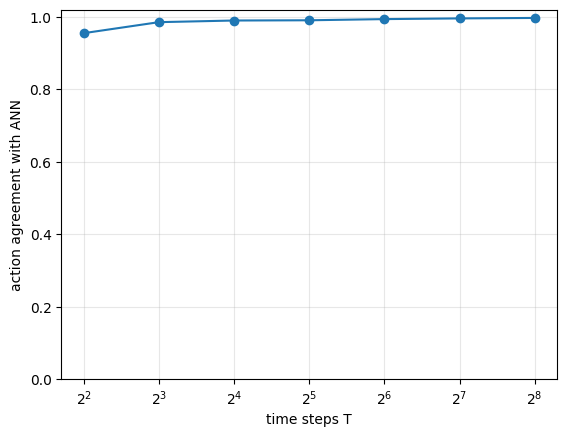

In [26]:
@torch.no_grad()
def agreement(s, m, x_all, T, bs=128):
    same = total = 0
    for i in range(0, len(x_all), bs):
        xb = x_all[i:i+bs].to(device)
        same += (m(xb).argmax(1) == s(xb, T).argmax(1)).sum().item()
        total += len(xb)
    return same / total

Ts = [4, 8, 16, 32, 64, 128, 256]
agree = {T: agreement(snn, model, test_frames, T) for T in Ts}
for T, a in agree.items():
    print(f"T={T:4d}  agreement = {a:.3f}")

plt.plot(list(agree), list(agree.values()), "o-"); plt.xscale("log", base=2)
plt.xlabel("time steps T"); plt.ylabel("action agreement with ANN"); plt.ylim(0, 1.02)
plt.grid(alpha=.3); plt.show()

Cell 8: percentile sweep (the main tuning knob)

In [27]:
sweep = {}
for p in [99.0, 99.9, 99.99, 100.0]:
    lam = get_lambdas(model, cal_frames, p)
    s = SpikingPlainCNN(model, lam).to(device).eval()
    sweep[p] = {T: agreement(s, model, test_frames, T) for T in [16, 32, 64, 128]}
    print(f"percentile {p}:", {T: round(a, 3) for T, a in sweep[p].items()})

percentile 99.0: {16: 0.988, 32: 0.991, 64: 0.99, 128: 0.99}
percentile 99.9: {16: 0.988, 32: 0.99, 64: 0.993, 128: 0.996}
percentile 99.99: {16: 0.988, 32: 0.995, 64: 0.997, 128: 0.998}
percentile 100.0: {16: 0.987, 32: 0.991, 64: 0.996, 128: 0.997}


Cell 9: in-game evaluation

Run this only after the offline numbers look reasonable.

In [28]:
def run_snn_episodes(s, T, n_episodes=50, action_repeat=ACTION_REPEAT):
    rewards = []
    for ep in range(n_episodes):
        obs, _ = env.reset()
        done = truncated = False
        total = 0.0
        while not (done or truncated):
            action = s(prep(obs).to(device), T).argmax(1).item()
            for _ in range(action_repeat):
                obs, r, done, truncated, _ = env.step(action)
                total += float(r)
                if done or truncated:
                    break
        rewards.append(total)
    return np.array(rewards)

results = {}
for T in [16, 32, 64]:
    r = run_snn_episodes(snn, T)
    results[T] = {"mean": float(r.mean()), "std": float(r.std()), "below0": int((r < 0).sum())}
    print(f"T={T}: {r.mean():.3f} ± {r.std():.3f}, below 0: {(r < 0).sum()}   (ANN reference 0.800 ± 0.116)")

T=16: 0.709 ± 0.539, below 0: 1   (ANN reference 0.800 ± 0.116)
T=32: 0.775 ± 0.156, below 0: 1   (ANN reference 0.800 ± 0.116)
T=64: 0.803 ± 0.094, below 0: 0   (ANN reference 0.800 ± 0.116)


In [29]:
BEST = 99.99
lambdas = get_lambdas(model, cal_frames, BEST)
print("lambdas:", [round(l, 4) for l in lambdas])
snn = SpikingPlainCNN(model, lambdas).to(device).eval()

def run_episodes(policy, n_episodes=300, action_repeat=ACTION_REPEAT):
    rewards = []
    for ep in range(n_episodes):
        obs, _ = env.reset()
        done = truncated = False
        total = 0.0
        while not (done or truncated):
            with torch.no_grad():
                action = policy(prep(obs).to(device)).argmax(1).item()
            for _ in range(action_repeat):
                obs, r, done, truncated, _ = env.step(action)
                total += float(r)
                if done or truncated:
                    break
        rewards.append(total)
    return np.array(rewards)

def summarize(name, r):
    se = r.std() / np.sqrt(len(r))
    print(f"{name:10s} {r.mean():.3f} ± {r.std():.3f} (SE {se:.3f}) | below 0: {(r<0).sum()} | below 0.3: {(r<0.3).sum()} | n={len(r)}")

ann_r = run_episodes(model)
summarize("ANN", ann_r)
game = {}
for T in [8, 16, 32, 48, 64]:
    r = run_episodes(lambda x, T=T: snn(x, T))
    game[T] = r
    summarize(f"SNN T={T}", r)

lambdas: [148.4624, 43.1385, 38.5537, 67.2712]
ANN        0.786 ± 0.118 (SE 0.007) | below 0: 1 | below 0.3: 2 | n=300
SNN T=8    0.718 ± 0.497 (SE 0.029) | below 0: 6 | below 0.3: 7 | n=300
SNN T=16   0.753 ± 0.341 (SE 0.020) | below 0: 4 | below 0.3: 8 | n=300
SNN T=32   0.798 ± 0.115 (SE 0.007) | below 0: 0 | below 0.3: 2 | n=300
SNN T=48   0.776 ± 0.299 (SE 0.017) | below 0: 1 | below 0.3: 2 | n=300
SNN T=64   0.791 ± 0.110 (SE 0.006) | below 0: 0 | below 0.3: 1 | n=300


In [30]:
# --- save the converted SNN (rescaled weights + everything needed to rebuild it) ---
torch.save({
    "state_dict": snn.state_dict(),
    "lambdas": lambdas,
    "percentile": 99.99,
    "v_init": snn.v_init,
    "action_repeat": ACTION_REPEAT,
}, f"{SAVE_DIR}/snn_converted_v2.pt")
print("saved snn_converted_v2.pt")

# --- run episodes on the SNN ---
T_FINAL = 32          # headline T; 64 is the conservative choice
N_EPISODES = 300

snn_r = run_episodes(lambda x: snn(x, T_FINAL), n_episodes=N_EPISODES)
summarize(f"SNN T={T_FINAL}", snn_r)

# save the per-episode rewards so you can re-analyse later
np.save(f"{SAVE_DIR}/snn_T{T_FINAL}_rewards.npy", snn_r)

saved snn_converted_v2.pt
SNN T=32   0.792 ± 0.110 (SE 0.006) | below 0: 0 | below 0.3: 2 | n=300


In [31]:
# Layer sizes for this network (from the shapes in your PlainCNN)
n_neurons = [32*17*31, 64*7*14, 128*3*6, 512]           # conv1, conv2, conv3, fc outputs
macs = {"conv1": 3_237_888, "conv2": 3_211_264, "conv3": 1_327_104, "fc": 1_179_648, "head": 2_048}
ann_macs = sum(macs.values())                           # ~8.96M per decision

@torch.no_grad()
def spike_stats(s, x_all, T, bs=64):
    totals = np.zeros(4); n = 0
    for i in range(0, len(x_all), bs):
        x = x_all[i:i+bs].to(device)
        v = [None]*4
        for _ in range(T):
            v[0], s1 = if_step(v[0], s.conv1(x), v_init=s.v_init)
            v[1], s2 = if_step(v[1], s.conv2(s1), v_init=s.v_init)
            v[2], s3 = if_step(v[2], s.conv3(s2), v_init=s.v_init)
            v[3], s4 = if_step(v[3], s.fc(s.flatten(s3)), v_init=s.v_init)
            for k, sp in enumerate([s1, s2, s3, s4]):
                totals[k] += sp.sum().item()
        n += len(x)
    return totals / n                                    # spikes per decision, per layer

for T in [32, 64]:
    spk = spike_stats(snn, test_frames[:500], T)
    rate = spk / (np.array(n_neurons) * T)
    # synaptic ops: each spike triggers (layer MACs / input neurons) accumulates in the next layer
    sops = (spk[0] * macs["conv2"]/n_neurons[0] + spk[1] * macs["conv3"]/n_neurons[1]
            + spk[2] * macs["fc"]/n_neurons[2]   + spk[3] * macs["head"]/n_neurons[3])
    dense_first = T * macs["conv1"]                      # conv1 sees analog input every step
    print(f"T={T}: spikes/decision per layer {spk.round(0)} | total {spk.sum():.0f}")
    print(f"      firing rate/neuron/step {rate.round(3)}")
    print(f"      SNN: {dense_first/1e6:.2f}M dense MACs (layer 1) + {sops/1e6:.2f}M accumulates"
          f" | ANN: {ann_macs/1e6:.2f}M MACs")

T=32: spikes/decision per layer [14417. 35472. 18367.  2307.] | total 70563
      firing rate/neuron/step [0.027 0.177 0.249 0.141]
      SNN: 103.61M dense MACs (layer 1) + 19.66M accumulates | ANN: 8.96M MACs
T=64: spikes/decision per layer [28885. 70577. 36481.  4583.] | total 140528
      firing rate/neuron/step [0.027 0.176 0.247 0.14 ]
      SNN: 207.22M dense MACs (layer 1) + 39.13M accumulates | ANN: 8.96M MACs


PlainCNN weights == original checkpoint weights

This re-confirms Step 3's sanity check directly on the actual tensors, not just the resulting reward:

In [ ]:
import torch

max_diff = 0.0
for sf_name, local_name in key_map.items():
    original = state_dict[sf_name].float()
    rebuilt = dict(model.named_parameters())[local_name].detach().cpu()
    diff = (original - rebuilt).abs().max().item()
    max_diff = max(max_diff, diff)
    status = "OK" if diff < 1e-6 else "MISMATCH"
    print(f"{local_name:20s} max diff: {diff:.2e}  [{status}]")

print(f"\nOverall max difference: {max_diff:.2e}")
print("PASS" if max_diff < 1e-6 else "FAIL -- re-check key_map")

SNN weights == PlainCNN weights, consistently rescaled

Since I haven't seen the exact formula your earlier rescaling cell used, this check doesn't assume a specific formula — instead it verifies the property any correct rescaling method must have: every weight in a given layer should be multiplied by the same single factor, not an inconsistent mix:

In [ ]:
layers = ["conv1", "conv2", "conv3", "fc"]

for layer_name in layers:
    plain_w = dict(model.named_parameters())[f"{layer_name}.weight"].detach().cpu().flatten()
    snn_w = dict(snn.named_parameters())[f"{layer_name}.weight"].detach().cpu().flatten()

    # Elementwise ratio, ignoring near-zero weights (division noise)
    mask = plain_w.abs() > 1e-6
    ratios = (snn_w[mask] / plain_w[mask])

    print(f"{layer_name:8s} scale factor: mean={ratios.mean():.4f}  std={ratios.std():.4f}  "
          f"(std should be ~0 if scaling is a single clean per-layer factor)")

Cell C: Saved file == in-memory SNN (round-trip integrity)

In [ ]:
import torch

saved = torch.load(f"{SAVE_DIR}/snn_converted_v2.pt", map_location="cpu")
saved_state = saved["state_dict"]

max_diff = 0.0
for name, param in snn.state_dict().items():
    reloaded = saved_state[name].float().cpu()
    original = param.float().cpu()
    diff = (reloaded - original).abs().max().item()
    max_diff = max(max_diff, diff)

print(f"Max difference between saved file and in-memory SNN: {max_diff:.2e}")
print("PASS" if max_diff < 1e-6 else "FAIL -- saved file does not match in-memory model")

In [ ]:
Cell D: Efficiency — spike counts and MACs

This is the same measurement code from your earlier T=32/T=64 result — re-run it here against this latest converted model so the numbers in your report correspond to the actual checkpoint you're reporting on, not an earlier run:

In [ ]:
n_neurons = [32*17*31, 64*7*14, 128*3*6, 512]  # conv1, conv2, conv3, fc outputs
macs = {"conv1": 3_237_888, "conv2": 3_211_264, "conv3": 1_327_104, "fc": 1_179_648, "head": 2_048}
ann_macs = sum(macs.values())

@torch.no_grad()
def spike_stats(s, x_all, T, bs=64):
    totals = np.zeros(4); n = 0
    for i in range(0, len(x_all), bs):
        x = x_all[i:i+bs].to(device)
        v = [None]*4
        for _ in range(T):
            v[0], s1 = if_step(v[0], s.conv1(x), v_init=s.v_init)
            v[1], s2 = if_step(v[1], s.conv2(s1), v_init=s.v_init)
            v[2], s3 = if_step(v[2], s.conv3(s2), v_init=s.v_init)
            v[3], s4 = if_step(v[3], s.fc(s.flatten(s3)), v_init=s.v_init)
            for k, sp in enumerate([s1, s2, s3, s4]):
                totals[k] += sp.sum().item()
        n += len(x)
    return totals / n

for T in [32, 64]:
    spk = spike_stats(snn, test_frames[:500], T)
    rate = spk / (np.array(n_neurons) * T)
    sops = (spk[0] * macs["conv2"]/n_neurons[0] + spk[1] * macs["conv3"]/n_neurons[1]
            + spk[2] * macs["fc"]/n_neurons[2]   + spk[3] * macs["head"]/n_neurons[3])
    dense_first = T * macs["conv1"]
    print(f"T={T}: spikes/decision per layer {spk.round(0)} | total {spk.sum():.0f}")
    print(f"      firing rate/neuron/step {rate.round(3)}")
    print(f"      SNN: {dense_first/1e6:.2f}M dense MACs (layer 1) + {sops/1e6:.2f}M accumulates"
          f" | ANN: {ann_macs/1e6:.2f}M MACs")